# 01 — Exploratory data analysis (BRFSS 2015 → `_MICHD`)

**Goal:** understand the data and collect the evidence for every preprocessing decision
(implemented later in `preprocessing.py`). Numpy + matplotlib only, as required by the project rules.

**Inputs**
- `data/dataset/*.csv` (not in git, see `data/README.md`).
- `eda/special_codes.json`: per-column codebook rules built from the official
  [BRFSS 2015 codebook](https://www.cdc.gov/brfss/annual_data/annual_2015.html): which values mean
  *don't know / refused / not applicable* (→ NaN), which mean *none / never* (→ 0), unit encodings and scale factors.
- `eda/column_decisions.csv`: one row per column with meaning, type and recommended action.

**Outputs:** figures in `report/figures/` and the list of decisions in section 11.

### Summary of findings

| Topic | Finding | Consequence for preprocessing / modelling |
|---|---|---|
| Imbalance | 8.8% positives (10.3 : 1); "always −1" = 91% accuracy, F1 0 | Evaluate with F1, stratified folds, tune the threshold |
| Missing values | 0 complete rows; 147 / 321 columns > 50% NaN; same rates in train and test | Impute (never drop rows); drop near-empty columns |
| Skip logic | e.g. BPMEDS is NaN in 100% of people without high blood pressure, 0% of the others | Fill structural NaN with the logical value (no / 0 / never) |
| Informative NaN | 132 / 191 partially-missing columns change P(y) by > 0.02 when missing | Missing indicators for the remaining (non-structural) NaN |
| Special codes | 7/9, 77/99 = don't know, 9 = not applicable, 88 = none, unit codes, ×100 columns | Per-column mapping (`eda/special_codes.json`) |
| Signal | Age, general health, blood pressure, cholesterol, stroke, diabetes, limitations; sex matters once age is known | Linear models are adequate; keep ordinal effects numeric; no top-k selection by marginal MI |
| Redundancy | 6 constant columns, 7 exact duplicate pairs, 44 pairs with abs(r) > 0.9 (non-nominal) | Keep one column per group |
| Leakage | HAREHAB1 answered ⇒ 100% positive (2.7% of positives); aspirin questions | Exclude from the main model, ablation row |
| Outliers | Drinks / activity minutes extremely skewed | log1p for counts (p99 clipping optional), then standardize |
| Landline | Higher rate only because landline respondents are older | Drop the phone-screening block |
| Shift | None (max 0.02 std) | CV ≈ test performance |
| Threshold | F1 0.22 at 0.5 → 0.42 at ≈0.20 (logistic, 15 features); class weights add nothing | Tune the threshold on the training folds inside CV |

Sections: 1 Labels & imbalance · 2 Column types · 3 Missing values · 4 Special codes · 5 Relation with the label ·
6 Redundancy · 7 Leakage · 8 Distributions & outliers · 9 Train/test shift · 10 Imbalance & threshold · 11 Decisions

In [1]:
import csv
import hashlib
import json
import os
import re
import sys

sys.path.append("..")  # import the project modules from the repo root

import numpy as np
import matplotlib.pyplot as plt

from helpers import load_csv_data
from implementations import logistic_regression, ridge_regression, sigmoid
from metrics import precision_recall_f1, predict_labels

DATA_PATH = "../data/dataset"
CACHE_DIR = "../data/cache"
FIG_DIR = "../report/figures"
SEED = 42

# Main analysis thresholds (plot sizes and display limits stay inline).
SURVEY_TYPES = ("admin", "id", "date", "weight")  # columns describing the survey, not the person
LEAKAGE = ("HAREHAB1", "CVDASPRN", "RDUCHART", "RDUCSTRK", "ASPUNSAF", "RLIVPAIN")  # see section 7
MIN_EFFECT = 0.02  # difference in positive rate considered meaningful
ASKED_MIN_SHARE = 0.05  # a state "asks" a question if more than 5% of its rows answered it
CORR_REDUNDANT = 0.9  # |correlation| above which two columns are considered redundant
SUBSAMPLE = 50_000  # rows used to compute correlation matrices
PARTIAL_NAN = (0.01, 0.99)  # a column is "partially missing" between these NaN rates
HIGH_NAN = 0.5  # NaN rate above which a column is "mostly missing"
SHIFT_MAX = 0.05  # train/test mean difference (in train std) considered a shift

os.makedirs(CACHE_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 0. Load the data

`load_csv_data` (provided `helpers.py`) parses ~320 MB of csv with `np.genfromtxt`, which takes a while.
We cache the arrays in `data/cache/raw.npz` (git-ignored) so the next runs take a few seconds.
The column names are read from the csv header, because `load_csv_data` drops them.

In [2]:
def load_data_cached(data_path=DATA_PATH, cache_dir=CACHE_DIR):
    '''Load the csv files with helpers.load_csv_data once and cache them as .npz.

    Returns:
        x_train, x_test, y_train, train_ids, test_ids (as returned by load_csv_data).
    '''
    names = ["x_train", "x_test", "y_train", "train_ids", "test_ids"]
    cache = os.path.join(cache_dir, "raw.npz")
    if not os.path.exists(cache):
        np.savez(cache, **dict(zip(names, load_csv_data(data_path))))
    with np.load(cache) as data:
        return tuple(data[name] for name in names)


def load_feature_names(data_path=DATA_PATH):
    '''Return the 321 feature names from the csv header (load_csv_data drops them).'''
    with open(os.path.join(data_path, "x_train.csv")) as f:
        return f.readline().strip().split(",")[1:]


x_train, x_test, y_train, train_ids, test_ids = load_data_cached()
cols = load_feature_names()
assert len(cols) == x_train.shape[1]
ix = {name: j for j, name in enumerate(cols)}
y01 = (y_train == 1).astype(float)  # labels in {0, 1}, convenient for rates
N, D = x_train.shape

with open("../eda/special_codes.json") as f:
    SPEC = json.load(f)
with open("../eda/column_decisions.csv") as f:
    DEC = {row["name"]: row for row in csv.DictReader(f)}
ctype = np.array([DEC[name]["type"] for name in cols])
is_survey = np.isin(ctype, SURVEY_TYPES)


def feature(name, x=x_train):
    '''Return column `name` of x (the raw training matrix by default).'''
    return x[:, ix[name]]


def pos_rate(mask, y=y01):
    '''Return P(y = 1) among the rows selected by the boolean mask (NaN if the mask is empty).'''
    return y[mask].mean() if mask.any() else np.nan


print(f"x_train {x_train.shape} | x_test {x_test.shape} | y_train {y_train.shape} | {len(cols)} names")

x_train (328135, 321) | x_test (109379, 321) | y_train (328135,) | 321 names


## 1. Labels and class imbalance

The label `_MICHD` is a CDC calculated variable: **+1** if the person was ever told they had a heart attack (CVDINFR4)
**or** angina / coronary heart disease (CVDCRHD4). Those two source questions are **not** in the dataset.
It is a *"has ever been diagnosed"* label, so consequences of the disease (medication, poor health, limitations)
are legitimately predictive.

In [3]:
prevalence = y01.mean()
print(f"Positives: {int(y01.sum()):,} / {N:,} = {prevalence:.2%}  ->  imbalance {(1 - prevalence) / prevalence:.1f} : 1")
print(f"Trivial 'always -1': accuracy {1 - prevalence:.3f}, F1 0.000")
print(f"Trivial 'always +1': accuracy {prevalence:.3f}, F1 {2 * prevalence / (1 + prevalence):.3f}")

Positives: 28,975 / 328,135 = 8.83%  ->  imbalance 10.3 : 1
Trivial 'always -1': accuracy 0.912, F1 0.000
Trivial 'always +1': accuracy 0.088, F1 0.162


**Takeaway.** Accuracy is useless here (91% by predicting that nobody is sick). The AIcrowd ranking uses **F1**,
so every model must be evaluated with F1 and the decision threshold must be tuned (section 10).

## 2. Column types

All 321 columns are numeric codes. Using the codebook we classified each one (`eda/column_decisions.csv`):

In [4]:
for col_type, count in zip(*np.unique(ctype, return_counts=True)):
    examples = ", ".join(np.array(cols)[ctype == col_type][:6])
    print(f"{col_type:11s}{count:4d}   e.g. {examples}")

admin        23   e.g. FMONTH, IDATE, IMONTH, IDAY, IYEAR, DISPCODE
binary      108   e.g. LANDLINE, HLTHPLN1, MEDCOST, BPMEDS, BLOODCHO, TOLDHI2
continuous   38   e.g. DIABAGE2, WEIGHT2, HEIGHT3, EXERHMM1, EXERHMM2, ASTHMAGE
count        44   e.g. NUMADULT, NUMMEN, NUMWOMEN, HHADULT, PHYSHLTH, MENTHLTH
date          2   e.g. FLSHTMY2, HIVTSTD3
id            2   e.g. SEQNO, _PSU
nominal      48   e.g. _STATE, PERSDOC2, BPHIGH4, DIABETE3, MARITAL, RENTHOM1
ordinal      50   e.g. GENHLTH, CHECKUP1, CHOLCHK, EDUCA, INCOME2, SMOKDAY2
weight        6   e.g. _STRWT, _RAWRAKE, _WT2RAKE, _CLLCPWT, _DUALCOR, _LLCPWT


- **admin / id / weight**: interview dates, sequence numbers, phone-screening questions, survey weights. They describe
  *how* the survey was run, not the person → drop.
- **date** (2 columns): month/year of the last flu shot and last HIV test. Health answers, but the date itself has
  little value (the yes/no questions FLUSHOT6 and HIVTST6 carry the information) → drop.
- **binary** (mostly 1 = yes, 2 = no, 7 = don't know, 9 = refused) → recode to 1/0.
- **ordinal** (e.g. GENHLTH 1 = excellent … 5 = poor, income and education levels) → keep as numbers.
- **nominal** (e.g. marital status, employment, race, and BPHIGH4 / DIABETE3 whose codes 2 and 4 mean
  *only during pregnancy* and *borderline / pre-diabetes*) → one-hot encode.
- **continuous / count** (age, BMI, days of poor health, drinks per week, minutes of activity) → keep,
  clean codes and units, clip / log the tails.

## 3. Missing values

### 3.1 How much is missing?

Columns with no NaN: 82
Columns with > 10% NaN: 182
Columns with > 50% NaN: 147
Columns with > 80% NaN: 116
Columns with > 90% NaN: 99
Columns with > 99% NaN: 30
Fraction of NaN per row: mean 44.8%, min 24.9%, max 67.9%
Rows without any NaN: 0
Max |NaN rate train - NaN rate test| over columns: 0.0040


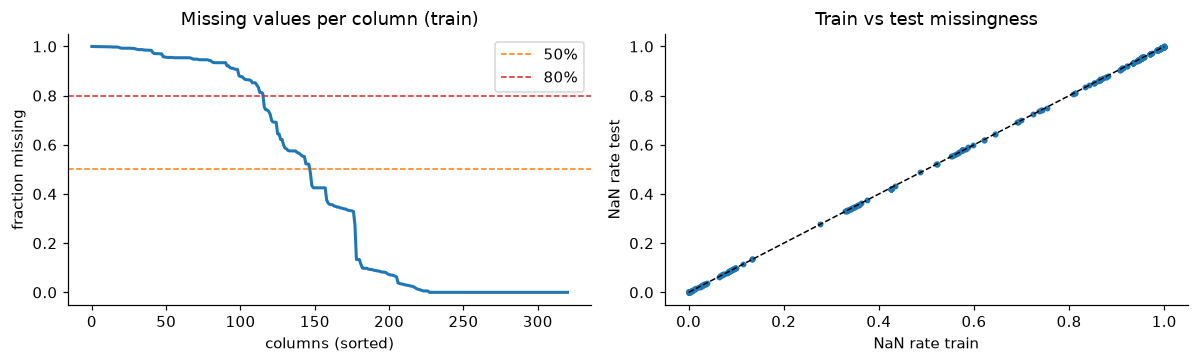

In [5]:
nan_tr = np.isnan(x_train).mean(axis=0)
nan_te = np.isnan(x_test).mean(axis=0)
row_nan = np.isnan(x_train).mean(axis=1)
print(f"Columns with no NaN: {(nan_tr == 0).sum()}")
for level in [0.1, 0.5, 0.8, 0.9, 0.99]:
    print(f"Columns with > {level:.0%} NaN: {(nan_tr > level).sum()}")
print(f"Fraction of NaN per row: mean {row_nan.mean():.1%}, min {row_nan.min():.1%}, max {row_nan.max():.1%}")
print(f"Rows without any NaN: {(row_nan == 0).sum()}")
print(f"Max |NaN rate train - NaN rate test| over columns: {np.abs(nan_tr - nan_te).max():.4f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(np.sort(nan_tr)[::-1], lw=2)
for level, color in [(0.5, "tab:orange"), (0.8, "tab:red")]:
    ax[0].axhline(level, ls="--", c=color, lw=1, label=f"{level:.0%}")
ax[0].set(xlabel="columns (sorted)", ylabel="fraction missing", title="Missing values per column (train)")
ax[0].legend()
ax[1].scatter(nan_tr, nan_te, s=8)
ax[1].plot([0, 1], [0, 1], "k--", lw=1)
ax[1].set(xlabel="NaN rate train", ylabel="NaN rate test", title="Train vs test missingness")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/missing_per_column.png", bbox_inches="tight")
plt.show()

**Takeaways.**
- Missingness is massive: no row is complete, so **dropping rows is impossible** (and we must predict every test row
  anyway). We need imputation.
- Missingness is the same in train and test → whatever rule we learn on train transfers to test.
- The sorted curve has plateaus: groups of columns missing together. They come from the questionnaire structure (3.3)
  and from optional modules asked only in some states (3.4).

### 3.2 Is missingness informative?

If people with a missing value have a different disease rate than people who answered, *the fact of being missing is
information*, and imputing a value would erase it. We compare P(y = 1 | NaN) with P(y = 1 | observed) for every
**partially-missing** column, defined here as 1%–99% NaN.

column      NaN rate  P(y=1|NaN)  P(y=1|obs)   meaning
DIABAGE2       87.1%       0.069       0.221   How old were you when you were told you have diabetes?
CDDISCUS       97.1%       0.084       0.227   Have you or anyone else discussed your confusion or mem
CDSOCIAL       97.1%       0.084       0.227   During the past 12 months; how often has confusion or m
CDASSIST       97.1%       0.084       0.227   As a result of confusion or memory loss; how often do y
CDHOUSE        97.1%       0.084       0.227   During the past 12 months; as a result of confusion or 
BLDSUGAR       93.4%       0.079       0.219   About how often do you check your blood for glucose or 
DIABEYE        93.4%       0.079       0.219   Has a doctor ever told you that diabetes has affected y
DIABEDU        93.4%       0.079       0.219   Have you ever taken a course or class in how to manage 
INSULIN        93.4%       0.079       0.219   Are you now taking insulin?
DOCTDIAB       93.4%       0.079       0.219   

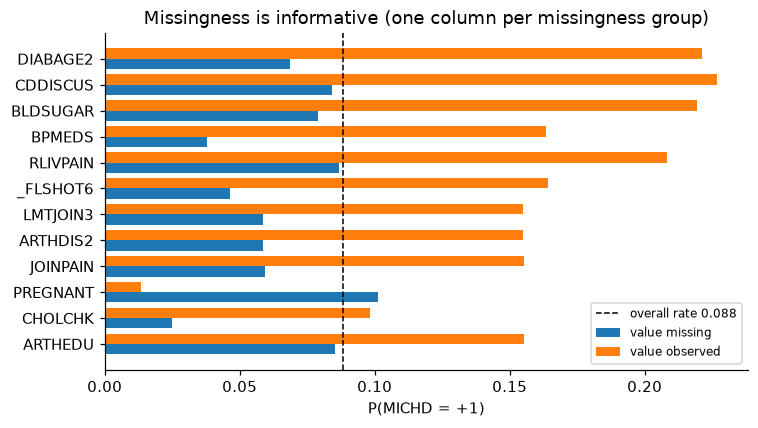

In [6]:
partial = []  # (name, nan_rate, P(y|NaN), P(y|observed))
for j, name in enumerate(cols):
    is_nan = np.isnan(x_train[:, j])
    if PARTIAL_NAN[0] < is_nan.mean() < PARTIAL_NAN[1]:
        partial.append((name, is_nan.mean(), pos_rate(is_nan), pos_rate(~is_nan)))
partial.sort(key=lambda row: -abs(row[2] - row[3]))

print(f"{'column':10s}{'NaN rate':>10s}{'P(y=1|NaN)':>12s}{'P(y=1|obs)':>12s}   meaning")
for name, nan_rate, rate_nan, rate_obs in partial[:15]:
    print(f"{name:10s}{nan_rate:10.1%}{rate_nan:12.3f}{rate_obs:12.3f}   {DEC[name]['description'][:55]}")
n_informative = sum(abs(rate_nan - rate_obs) > MIN_EFFECT for _, _, rate_nan, rate_obs in partial)
print(f"\n{n_informative} of {len(partial)} partially-missing columns: |P(y|NaN) - P(y|obs)| > {MIN_EFFECT}")

# Plot one column per group of columns that are missing together (same rates), for readability.
seen, shown = set(), []
for row in partial:
    key = (round(row[1], 3), round(row[2], 3))
    if key not in seen:
        seen.add(key)
        shown.append(row)
shown = shown[:12][::-1]
fig, ax = plt.subplots(figsize=(7, 4))
pos = np.arange(len(shown))
ax.barh(pos - 0.2, [row[2] for row in shown], 0.4, label="value missing")
ax.barh(pos + 0.2, [row[3] for row in shown], 0.4, label="value observed")
ax.axvline(prevalence, c="k", ls="--", lw=1, label=f"overall rate {prevalence:.3f}")
ax.set_yticks(pos)
ax.set_yticklabels([row[0] for row in shown])
ax.set(xlabel="P(MICHD = +1)", title="Missingness is informative (one column per missingness group)")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/informative_missingness.png", bbox_inches="tight")
plt.show()

**Takeaways.**
- For most partially-missing columns the disease rate changes when the value is missing → for the kept columns,
  **add a binary "was missing" indicator** before imputing.
- Caveat: the most "informative" columns are missing *because of* a previous answer (diabetes module ⇔ has diabetes,
  BPMEDS ⇔ has high blood pressure, `_FLSHOT6` ⇔ aged 65+). For them the indicator only repeats the parent question;
  they are better handled by the structural fill of 3.3.

### 3.3 Structural missingness (skip logic)

Many questions are only asked depending on a previous answer (e.g. *"do you take medication for high blood
pressure?"* is only asked to people with high blood pressure). Then NaN does not mean *unknown*: it means
*"no / zero"*. We verify each codebook rule by comparing the NaN rate when the question was **skipped** with the
NaN rate when it was **asked**:

In [7]:
def skip_check(target, skipped, asked, desc):
    '''Print the NaN rate of `target` among rows that skipped the question vs rows that were asked it.'''
    is_nan = np.isnan(feature(target))
    print(f"{target:9s} {desc:46s} skipped: {is_nan[skipped].mean():6.1%}   asked: {is_nan[asked].mean():6.1%}")


bphigh, alcday = feature("BPHIGH4"), feature("ALCDAY5")
phys, ment = feature("PHYSHLTH"), feature("MENTHLTH")
skip_check("BPMEDS", np.isin(bphigh, [2, 3, 4]), bphigh == 1, "only if high blood pressure (BPHIGH4 = 1)")
skip_check("CHOLCHK", feature("BLOODCHO") == 2, feature("BLOODCHO") == 1, "only if cholesterol checked")
skip_check("SMOKDAY2", feature("SMOKE100") == 2, feature("SMOKE100") == 1, "only if smoked 100 cigarettes")
skip_check("AVEDRNK2", alcday == 888, (alcday >= 101) & (alcday <= 230), "only if drank in last 30 days")
skip_check("POORHLTH", (phys == 88) & (ment == 88), ((phys >= 1) & (phys <= 30)) | ((ment >= 1) & (ment <= 30)),
           "only if some bad physical/mental days")
skip_check("DIABAGE2", np.isin(feature("DIABETE3"), [2, 3, 4]), feature("DIABETE3") == 1, "only if diabetes")
skip_check("JOINPAIN", feature("HAVARTH3") == 2, feature("HAVARTH3") == 1, "only if arthritis")
skip_check("INSULIN", np.isin(feature("DIABETE3"), [2, 3, 4]), feature("DIABETE3") == 1, "only if diabetes")
skip_check("PA1MIN_", feature("EXERANY2") == 2, feature("EXERANY2") == 1, "only if any exercise")

complete = feature("DISPCODE") == 1100  # 1100 = completed interview, 1200 = partial (break-off)
arthritis = feature("HAVARTH3") == 1
joinpain_nan = np.isnan(feature("JOINPAIN"))
print(f"\nJOINPAIN NaN among people with arthritis: completed interviews "
      f"{joinpain_nan[arthritis & complete].mean():.1%}, partial interviews {joinpain_nan[arthritis & ~complete].mean():.1%}")

BPMEDS    only if high blood pressure (BPHIGH4 = 1)      skipped: 100.0%   asked:   0.0%
CHOLCHK   only if cholesterol checked                    skipped: 100.0%   asked:   0.0%
SMOKDAY2  only if smoked 100 cigarettes                  skipped: 100.0%   asked:   0.1%
AVEDRNK2  only if drank in last 30 days                  skipped: 100.0%   asked:   0.2%
POORHLTH  only if some bad physical/mental days          skipped: 100.0%   asked:   0.0%
DIABAGE2  only if diabetes                               skipped: 100.0%   asked:   0.0%
JOINPAIN  only if arthritis                              skipped: 100.0%   asked:   9.6%
INSULIN   only if diabetes                               skipped: 100.0%   asked:  48.6%
PA1MIN_   only if any exercise                           skipped: 100.0%   asked:   2.4%

JOINPAIN NaN among people with arthritis: completed interviews 1.6%, partial interviews 65.8%


**Takeaways.**
- When the question is skipped the column is NaN in 100% of the rows → for these columns NaN is **structural** and is
  filled with its logical value (*no medication*, *no insulin*, *never checked*, *not at all*, *0 drinks*, *0 poor-health days*,
  *0 minutes of activity*, *no joint pain*), not with the median.
- The few NaN left among people who *were* asked are not "don't know" answers (those have their own codes, section 4):
  they come from **interviews interrupted before the end** (partial interviews have far more NaN) or from a parent
  question that is itself missing. These are true unknowns → impute + missing indicator.

### 3.4 Optional modules and the landline / cell-phone split

Columns with > 50% NaN: are they asked everywhere (skip logic) or only in some states (optional modules)?

147 columns with > 50% NaN, by number of states (of 53) where they were asked:
  0 states (nested skip logic / screeners)           7   e.g. CDHELP, ASERVIST, ASDRVIST, STREHAB1
  1-10 states (optional state modules)              70   e.g. VIDFCLT2, VIREDIF3, VIPRFVS2, VINOCRE2, VIEYEXM2, VIINSUR2, VICTRCT4, VIGLUMA2
  11-44 states (modules in many states)             39   e.g. PDIABTST, PREDIAB1, INSULIN, BLDSUGAR, FEETCHK2, DOCTDIAB, CHKHEMO3, EYEEXAM
  >= 45 states (core questions with skip logic)     31   e.g. LANDLINE, HHADULT, BPMEDS, ASTHNOW, DIABAGE2, PREGNANT, SMOKDAY2, STOPSMK2
Mean fraction of NaN per row: y = -1 44.85%, y = +1 44.12%

Landline: 57.5% of rows, P(y=1) = 0.107, mean age 61.3
Cell    : 42.5% of rows, P(y=1) = 0.062, mean age 47.2
Within the same age group, landline has a higher rate in only 4 of 13 groups


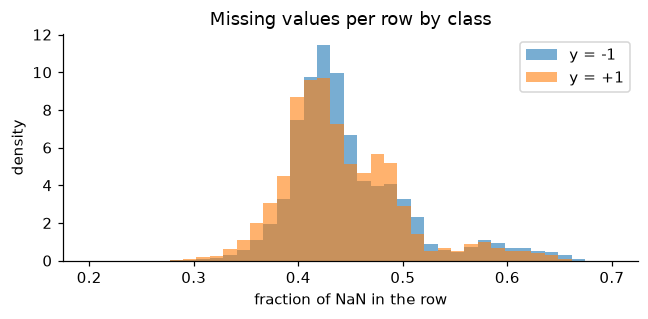

In [8]:
state = feature("_STATE")
states = np.unique(state)
high = np.where(nan_tr > HIGH_NAN)[0]
answered = np.array([(~np.isnan(x_train[state == s][:, high])).mean(axis=0) for s in states])  # (states, columns)
n_states = (answered > ASKED_MIN_SHARE).sum(axis=0)
buckets = [("0 states (nested skip logic / screeners)", n_states == 0),
           ("1-10 states (optional state modules)", (n_states >= 1) & (n_states <= 10)),
           ("11-44 states (modules in many states)", (n_states >= 11) & (n_states <= 44)),
           (">= 45 states (core questions with skip logic)", n_states >= 45)]
print(f"{len(high)} columns with > {HIGH_NAN:.0%} NaN, by number of states (of {len(states)}) where they were asked:")
for label, mask in buckets:
    families = {}
    for j in high[mask]:
        if not is_survey[j]:
            families.setdefault(cols[j][:3], cols[j])  # one example per question family
    print(f"  {label:48s}{mask.sum():4d}   e.g. {', '.join(list(families.values())[:8])}")

print(f"Mean fraction of NaN per row: y = -1 {row_nan[y01 == 0].mean():.2%}, y = +1 {row_nan[y01 == 1].mean():.2%}")

land = feature("QSTVER") < 20  # questionnaire versions < 20 are landline interviews
age_group = feature("_AGEG5YR")
age = feature("_AGE80")
print(f"\nLandline: {land.mean():.1%} of rows, P(y=1) = {pos_rate(land):.3f}, mean age {age[land].mean():.1f}")
print(f"Cell    : {(~land).mean():.1%} of rows, P(y=1) = {pos_rate(~land):.3f}, mean age {age[~land].mean():.1f}")
higher = sum(pos_rate(land & (age_group == g)) > pos_rate(~land & (age_group == g)) for g in range(1, 14))
print(f"Within the same age group, landline has a higher rate in only {higher} of 13 groups")

fig, ax = plt.subplots(figsize=(6, 3))
bins = np.linspace(0.2, 0.7, 40)
ax.hist(row_nan[y01 == 0], bins, density=True, alpha=0.6, label="y = -1")
ax.hist(row_nan[y01 == 1], bins, density=True, alpha=0.6, label="y = +1")
ax.set(xlabel="fraction of NaN in the row", ylabel="density", title="Missing values per row by class")
ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/missing_per_row.png", bbox_inches="tight")
plt.show()

**Takeaways.**
- Many near-empty columns are **optional modules** run by a handful of states (caregiving, vision, cognitive decline,
  HPV, cancer screening…); others are asked in more states but only to small sub-groups.
  For > 80–90% of people they are not asked, so they carry little usable information → **drop columns above a NaN
  threshold** (≈80%, tuned by CV), except the few strongly informative ones.
- Landline respondents have a higher disease rate, but **only because they are older**: within the same age group
  the difference disappears or even reverses. The whole phone-screening block is therefore dropped (no `is_landline` feature).
- The fraction of NaN per row is almost identical in both classes → not worth a feature (the small differences
  that a count of missing / *don't know* answers shows are again explained by age).

## 4. Special codes inside numeric columns

BRFSS stores answers like *don't know / refused* as numbers: 7/9, 77/99, 777/999. Calculated columns use 9 for
*don't know* but also for *not applicable*. 88 / 888 mean *none* (= 0), 555 means *never*, and several columns encode
the unit in the first digit (e.g. `ALCDAY5`: 1xx = days per week, 2xx = days per month). Fed as numbers,
*"refused"* (99) becomes *"99 days of poor health"*. The codes depend on the column, so the rules are per column.

column      NaN codes (DK/refused/N.A.)   share  P(y|code)  P(y|valid)
_CHISPNC                            [9]   58.4%      0.099       0.031
_HCVU651                            [9]   35.9%      0.163       0.046
_INCOMG                             [9]   17.9%      0.094       0.087
INCOME2                        [77, 99]   17.1%      0.095       0.087
_PAREC1                             [9]   13.0%      0.087       0.088
_PASTAE1                            [9]   13.0%      0.087       0.088
_PACAT1                             [9]   12.6%      0.086       0.089
_PA300R2                            [9]   12.6%      0.086       0.089
_PA30021                            [9]   12.6%      0.086       0.089
_PAINDX1                            [9]   12.0%      0.085       0.089
_PA150R2                            [9]   12.0%      0.085       0.089
_VEGLT1                             [9]   11.5%      0.095       0.087
_PASTRNG                            [9]    9.9%      0.083       0.089
_FRTLT

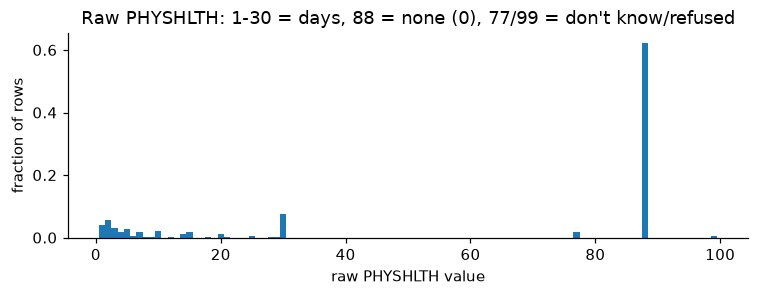

In [9]:
code_stats = []  # (name, codes, share of rows, P(y|code), P(y|valid value))
for j, name in enumerate(cols):
    codes = SPEC.get(name, {}).get("nan_codes", [])
    if not codes or is_survey[j]:
        continue
    values = x_train[:, j]
    has_code = np.isin(values, codes)
    if has_code.mean() >= 0.01:
        code_stats.append((name, codes, has_code.mean(), pos_rate(has_code), pos_rate(~has_code & ~np.isnan(values))))
code_stats.sort(key=lambda row: -row[2])
print(f"{'column':10s}{'NaN codes (DK/refused/N.A.)':>29s}{'share':>8s}{'P(y|code)':>11s}{'P(y|valid)':>12s}")
for name, codes, share, rate_code, rate_valid in code_stats[:15]:
    print(f"{name:10s}{str(codes):>29s}{share:8.1%}{rate_code:11.3f}{rate_valid:12.3f}")

print("\n'Don't know' (code 7) on health-condition questions:")
for name in ["CVDSTRK3", "CHCCOPD1", "CHCKIDNY", "TOLDHI2"]:
    values = feature(name)
    print(f"  {name:9s} yes: {pos_rate(values == 1):.3f}   no: {pos_rate(values == 2):.3f}   "
          f"don't know: {pos_rate(values == 7):.3f} (n = {int((values == 7).sum())})")
genhlth = feature("GENHLTH")
print(f"  GENHLTH   excellent: {pos_rate(genhlth == 1):.3f}   poor: {pos_rate(genhlth == 5):.3f}   "
      f"don't know: {pos_rate(genhlth == 7):.3f} (n = {int((genhlth == 7).sum())})")

physhlth = feature("PHYSHLTH")
values, counts = np.unique(physhlth[~np.isnan(physhlth)], return_counts=True)
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.bar(values, counts / N, width=1.0)
ax.set(xlabel="raw PHYSHLTH value", ylabel="fraction of rows",
       title="Raw PHYSHLTH: 1-30 = days, 88 = none (0), 77/99 = don't know/refused")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/special_codes_physhlth.png", bbox_inches="tight")
plt.show()

**Takeaways.**
- In several *calculated* columns the code 9 means *not applicable* rather than *don't know* (`_HCVU651` = 9 for
  everybody aged 65+, `_CHISPNC` = 9 for people without children) → that is why their P(y | code) is so different.
  The missing indicator keeps this information.
- Special codes are frequent (e.g. income *refused/don't know* ≈ 17% of rows) → mapping is necessary, per column,
  from `eda/special_codes.json`.
- `88 = none` is the **most common value** of PHYSHLTH: left as is, it would be read as "88 days" → it must become 0.
- *Don't know* is not neutral (e.g. people who don't know whether they had a stroke have a much higher rate than
  those who answer *no*), but these groups are small (a few hundred to ≈2,000 rows, < 1% of the data) → after mapping the code to NaN, the
  missing indicator keeps that signal.

## 5. Relation with the label

From here on we work on a **cleaned** copy of the data, as the preprocessing will: special codes → NaN or 0,
unit codes converted to a common unit, scale factors applied, and the structural NaN of 3.3 filled.

In [10]:
TRANSFORMS = {name: re.search(r"transform=(\w+)", spec["notes"]).group(1)
              for name, spec in SPEC.items() if "transform=" in spec.get("notes", "")}


def convert_units(raw, kind):
    '''Convert BRFSS unit-encoded values to one unit (rules in eda/special_codes.json, "_transforms").'''
    out = raw.copy()

    def between(low, high):
        return (raw >= low) & (raw <= high)

    if kind == "weight2":  # 50-999 pounds, 9000-9998 kilograms -> kg
        out[between(50, 999)] = raw[between(50, 999)] * 0.45359
        out[between(9000, 9998)] = raw[between(9000, 9998)] - 9000
    elif kind == "height3":  # 200-711 feet+inches (510 = 5 ft 10 in), 9000-9998 centimetres -> cm
        ft_in = between(200, 711)
        out[ft_in] = (raw[ft_in] // 100 * 12 + raw[ft_in] % 100) * 2.54
        out[between(9000, 9998)] = raw[between(9000, 9998)] - 9000
    elif kind == "perweek_wm":  # 1xx = times per week, 2xx = times per month -> per week
        out[between(101, 199)] = raw[between(101, 199)] - 100
        out[between(201, 299)] = (raw[between(201, 299)] - 200) * 7 / 30
    elif kind == "food":  # 1xx per day, 2xx per week, 3xx per month -> per day
        out[between(101, 199)] = raw[between(101, 199)] - 100
        out[between(201, 299)] = (raw[between(201, 299)] - 200) / 7
        out[between(301, 399)] = (raw[between(301, 399)] - 300) / 30
    elif kind == "peryear_dwmy":  # 1xx per day, 2xx per week, 3xx per month, 4xx per year -> per year
        for low, factor in ((100, 365), (200, 52), (300, 12), (400, 1)):
            out[between(low + 1, low + 99)] = (raw[between(low + 1, low + 99)] - low) * factor
    elif kind == "hhmm":  # hours and minutes (130 = 1 h 30) -> minutes
        known = ~np.isnan(raw)
        out[known] = raw[known] // 100 * 60 + raw[known] % 100
    return out


def clean_codes(x):
    '''Return a copy of x with special codes mapped, units converted and scale factors applied, per column.'''
    x = x.copy()
    for j, name in enumerate(cols):
        spec = SPEC.get(name)
        if not spec:
            continue
        raw = x[:, j].copy()
        if name in TRANSFORMS:
            x[:, j] = convert_units(raw, TRANSFORMS[name])
        x[np.isin(raw, spec["nan_codes"]), j] = np.nan
        x[np.isin(raw, spec["zero_codes"]), j] = 0
        for code_value, new_value in spec.get("recode", {}).items():
            x[raw == float(code_value), j] = new_value
        x[:, j] *= spec.get("scale", 1)
    return x


def fill_structural(xc, x_raw):
    '''Fill skip-logic NaN of the cleaned matrix xc with their logical value (rules verified in section 3.3).'''

    def fill(target, skipped, value):
        j = ix[target]
        xc[np.isnan(xc[:, j]) & skipped, j] = value

    no_drinks = feature("ALCDAY5", x_raw) == 888
    for name in ("AVEDRNK2", "DRNK3GE5", "MAXDRNKS"):
        fill(name, no_drinks, 0)
    fill("POORHLTH", (feature("PHYSHLTH", x_raw) == 88) & (feature("MENTHLTH", x_raw) == 88), 0)
    fill("BPMEDS", np.isin(feature("BPHIGH4", x_raw), [2, 3, 4]), 2)  # 2 = no medication
    fill("CHOLCHK", feature("BLOODCHO", x_raw) == 2, 5)  # 5 = never checked
    fill("SMOKDAY2", feature("SMOKE100", x_raw) == 2, 3)  # 3 = not at all
    no_exercise = feature("EXERANY2", x_raw) == 2
    for name in ("PA1MIN_", "PA1VIGM_"):
        fill(name, no_exercise, 0)
    fill("JOINPAIN", feature("HAVARTH3", x_raw) == 2, 0)  # 0 = no joint pain
    fill("INSULIN", np.isin(feature("DIABETE3", x_raw), [2, 3, 4]), 2)  # 2 = no insulin
    return xc


xc = fill_structural(clean_codes(x_train), x_train)
print(f"cleaned training matrix {xc.shape}; NaN share {np.isnan(x_train).mean():.1%} (raw) -> {np.isnan(xc).mean():.1%}")
for name in ["WEIGHT2", "HEIGHT3", "ALCDAY5", "_DRNKWEK"]:
    print(f"  {name:9s} median raw {np.nanmedian(feature(name)):8.1f} -> cleaned {np.nanmedian(feature(name, xc)):7.2f}")

cleaned training matrix (328135, 321); NaN share 44.8% (raw) -> 44.6%
  WEIGHT2   median raw    175.0 -> cleaned   77.56
  HEIGHT3   median raw    507.0 -> cleaned  167.64
  ALCDAY5   median raw    777.0 -> cleaned    0.23
  _DRNKWEK  median raw     23.0 -> cleaned    0.23


### 5.1 Main risk factors

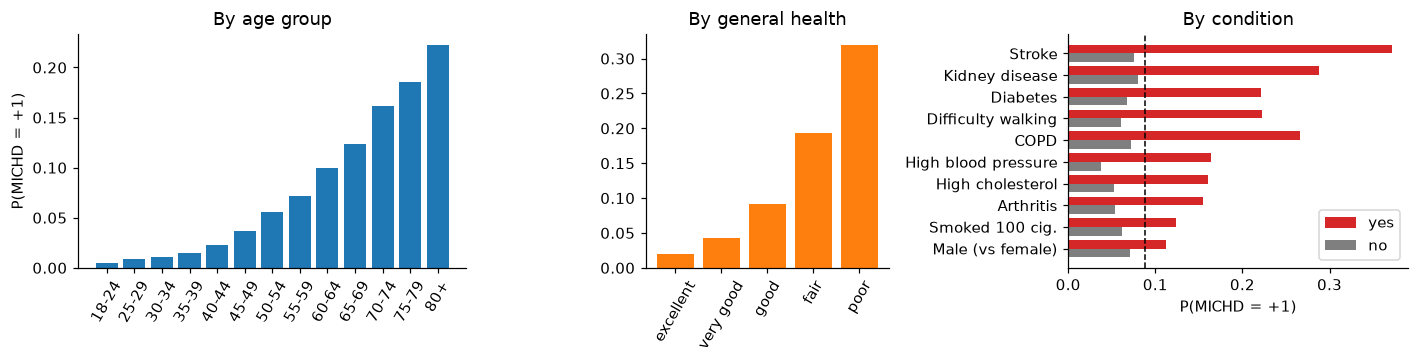

Stroke               yes 0.371   no 0.076   ratio  4.9x
Kidney disease       yes 0.288   no 0.081   ratio  3.6x
Diabetes             yes 0.221   no 0.067   ratio  3.3x
Difficulty walking   yes 0.223   no 0.060   ratio  3.7x
COPD                 yes 0.267   no 0.072   ratio  3.7x
High blood pressure  yes 0.163   no 0.037   ratio  4.4x
High cholesterol     yes 0.161   no 0.052   ratio  3.1x
Arthritis            yes 0.155   no 0.054   ratio  2.9x
Smoked 100 cig.      yes 0.124   no 0.062   ratio  2.0x
Male (vs female)     yes 0.112   no 0.071   ratio  1.6x
DIABETE3 [1 yes, 2 pregnancy only, 3 no, 4 pre-diabetes] -> 1: 0.221 (n=42223), 2: 0.040 (n=2675), 3: 0.067 (n=277049), 4: 0.145 (n=5709)
BPHIGH4 [1 yes, 2 pregnancy only, 3 no, 4 borderline] -> 1: 0.163 (n=131801), 2: 0.031 (n=2431), 3: 0.037 (n=189743), 4: 0.060 (n=3242)


In [11]:
AGE_LABELS = dict(zip(range(1, 14), ["18-24", "25-29", "30-34", "35-39", "40-44", "45-49", "50-54",
                                     "55-59", "60-64", "65-69", "70-74", "75-79", "80+"]))
HEALTH_LABELS = {1: "excellent", 2: "very good", 3: "good", 4: "fair", 5: "poor"}
# (label, column, codes meaning "yes", codes meaning "no")
FACTORS = [("Stroke", "CVDSTRK3", [1], [2]), ("Kidney disease", "CHCKIDNY", [1], [2]),
           ("Diabetes", "DIABETE3", [1], [3]), ("Difficulty walking", "DIFFWALK", [1], [2]),
           ("COPD", "CHCCOPD1", [1], [2]), ("High blood pressure", "BPHIGH4", [1], [3]),
           ("High cholesterol", "TOLDHI2", [1], [2]), ("Arthritis", "HAVARTH3", [1], [2]),
           ("Smoked 100 cig.", "SMOKE100", [1], [2]), ("Male (vs female)", "SEX", [1], [2])]


def rate_by_value(name):
    '''Return the distinct values of a cleaned column, P(y = 1) for each value and the counts.'''
    values = feature(name, xc)
    known = ~np.isnan(values)
    levels, inverse = np.unique(values[known], return_inverse=True)
    counts = np.bincount(inverse)
    return levels, np.bincount(inverse, weights=y01[known]) / counts, counts


fig, ax = plt.subplots(1, 3, figsize=(13, 3.4), gridspec_kw={"width_ratios": [1.6, 1, 1.4]})
for axis, name, labels, color, title in [(ax[0], "_AGEG5YR", AGE_LABELS, "tab:blue", "By age group"),
                                          (ax[1], "GENHLTH", HEALTH_LABELS, "tab:orange", "By general health")]:
    levels, rates, _ = rate_by_value(name)
    axis.bar(range(len(levels)), rates, color=color)
    axis.set_xticks(range(len(levels)))
    axis.set_xticklabels([labels[int(level)] for level in levels], rotation=60)
    axis.set(title=title)
ax[0].set_ylabel("P(MICHD = +1)")

rate_yes = [pos_rate(np.isin(feature(name, xc), yes)) for _, name, yes, _ in FACTORS]
rate_no = [pos_rate(np.isin(feature(name, xc), no)) for _, name, _, no in FACTORS]
pos = np.arange(len(FACTORS))[::-1]
ax[2].barh(pos + 0.2, rate_yes, 0.4, label="yes", color="tab:red")
ax[2].barh(pos - 0.2, rate_no, 0.4, label="no", color="tab:gray")
ax[2].set_yticks(pos)
ax[2].set_yticklabels([label for label, *_ in FACTORS])
ax[2].axvline(prevalence, c="k", ls="--", lw=1)
ax[2].set(xlabel="P(MICHD = +1)", title="By condition")
ax[2].legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/risk_factors.png", bbox_inches="tight")
plt.show()

for (label, *_), r_yes, r_no in zip(FACTORS, rate_yes, rate_no):
    print(f"{label:20s} yes {r_yes:.3f}   no {r_no:.3f}   ratio {r_yes / r_no:4.1f}x")
for name, meaning in [("DIABETE3", "1 yes, 2 pregnancy only, 3 no, 4 pre-diabetes"),
                      ("BPHIGH4", "1 yes, 2 pregnancy only, 3 no, 4 borderline")]:
    levels, rates, counts = rate_by_value(name)
    detail = ", ".join(f"{int(level)}: {rate:.3f} (n={count})" for level, rate, count in zip(levels, rates, counts))
    print(f"{name} [{meaning}] -> {detail}")

**Takeaways.** The classic cardiovascular risk factors show up clearly: the rate goes from ≈0.5% at 18–24 to > 20%
at 80+, and from ≈2% (excellent health) to > 30% (poor health). Stroke, kidney disease, diabetes, hypertension and
high cholesterol multiply the rate by about 3–5×.
- **Age and general health have a monotone effect** → keep them as ordinal / continuous numbers.
- Most yes/no questions use 1 = yes, 2 = no → recode to 1/0 so that the sign of the weights is readable.
- `DIABETE3` and `BPHIGH4` are **not** yes/no: *pre-diabetes* (code 4) has a rate between *yes* and *no*,
  and *only during pregnancy* (code 2) behaves like *no* → treat them as nominal (one-hot), not as numbers 1–4.

### 5.2 Ranking all features

Mutual information (MI) between each cleaned column and the label, keeping **NaN as its own category**
(so it also captures informative missingness), plus the correlation computed on observed values
(not computed for nominal columns, whose codes have no order).

  # column      MI x1e3    corr    NaN   meaning
  1 GENHLTH        43.6   0.249     0%   Would you say that in general your health is:
  2 _AGEG5YR       43.2   0.227     1%   Fourteen-level age category
  3 _AGE80         43.0   0.225     0%   Imputed Age value collapsed above 80
  4 MAXVO2_        42.1  -0.224     1%   Estimated Age-Gender Specific Maximum Oxygen 
  5 FC60_          42.1  -0.224     1%   Estimated Functional Capacity
  6 _AGE_G         39.9   0.207     0%   Six-level imputed age category
  7 EMPLOY1        38.3       -     1%   Are you currently…?
  8 BPMEDS         36.1  -0.232     0%   Are you currently taking medicine for your hi
  9 BPHIGH4        33.9       -     0%   Have you EVER been told by a doctor; nurse or
 10 _RFHYPE5       33.8   0.218     0%   Adults who have been told they have high bloo
 11 _RFHLTH        32.0   0.235     0%   Adults with good or better health
 12 _AGE65YR       28.0   0.204     1%   Two-level age category
 13 _HCVU651       26.8  -

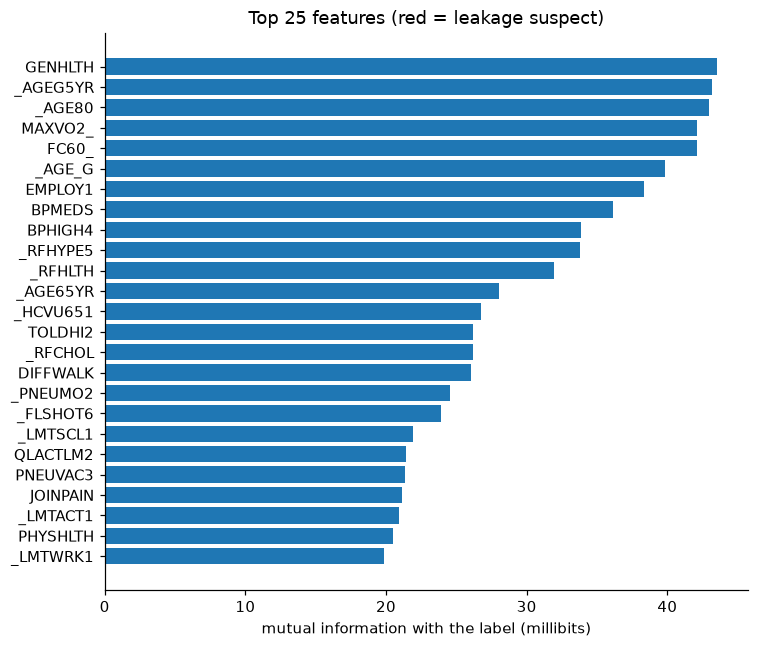


104 of 288 non-survey columns have MI < 1 millibit (almost no signal)
  _BMI5     rank 124, MI 3.6 millibits
  _DRNKWEK  rank  79, MI 6.2 millibits
  _FRUTSUM  rank 191, MI 0.9 millibits
  _VEGESUM  rank 166, MI 1.3 millibits


In [12]:
def mutual_info(values, y, max_bins=10):
    '''Mutual information in bits between a feature (NaN = own category) and a binary label y.

    Columns with more than 20 distinct values are discretized in max_bins quantile bins.
    '''
    is_nan = np.isnan(values)
    codes = np.zeros(len(values), dtype=int)
    observed = values[~is_nan]
    if observed.size:
        if np.unique(observed).size > 20:
            edges = np.unique(np.quantile(observed, np.linspace(0, 1, max_bins + 1)[1:-1]))
            codes[~is_nan] = np.digitize(observed, edges)
        else:
            codes[~is_nan] = np.unique(observed, return_inverse=True)[1]
    codes[is_nan] = codes.max() + 1
    n_codes = codes.max() + 1
    joint = np.bincount(codes * 2 + y.astype(int), minlength=2 * n_codes).reshape(n_codes, 2) / len(values)
    p_x, p_y = joint.sum(axis=1, keepdims=True), joint.sum(axis=0, keepdims=True)
    nonzero = joint > 0
    return float((joint[nonzero] * np.log2(joint[nonzero] / (p_x @ p_y)[nonzero])).sum())


def corr_observed(values, y):
    '''Pearson correlation between a feature and y on the rows where the feature is observed (0 if undefined).'''
    known = ~np.isnan(values)
    if known.sum() < 100 or np.std(values[known]) == 0 or np.std(y[known]) == 0:
        return 0.0
    return float(np.corrcoef(values[known], y[known])[0, 1])


rank = []  # (name, MI in millibits, correlation or NaN for nominal, NaN rate after cleaning)
for j, name in enumerate(cols):
    if is_survey[j]:
        continue
    corr = np.nan if ctype[j] == "nominal" else corr_observed(xc[:, j], y01)
    rank.append((name, 1000 * mutual_info(xc[:, j], y01), corr, np.isnan(xc[:, j]).mean()))
rank.sort(key=lambda row: -row[1])

print(f"{'#':>3s} {'column':10s}{'MI x1e3':>9s}{'corr':>8s}{'NaN':>7s}   meaning")
for k, (name, mi, corr, nan_rate) in enumerate(rank[:30], 1):
    corr_text = "-" if np.isnan(corr) else f"{corr:.3f}"
    flag = "  <- leakage (section 7)" if name in LEAKAGE else ""
    print(f"{k:3d} {name:10s}{mi:9.1f}{corr_text:>8s}{nan_rate:7.0%}   {DEC[name]['description'][:45]}{flag}")

shown = rank[:25][::-1]
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(range(len(shown)), [row[1] for row in shown],
        color=["tab:red" if row[0] in LEAKAGE else "tab:blue" for row in shown])
ax.set_yticks(range(len(shown)))
ax.set_yticklabels([row[0] for row in shown])
ax.set(xlabel="mutual information with the label (millibits)", title="Top 25 features (red = leakage suspect)")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/feature_ranking.png", bbox_inches="tight")
plt.show()

n_weak = sum(mi < 1 for _, mi, _, _ in rank)
print(f"\n{n_weak} of {len(rank)} non-survey columns have MI < 1 millibit (almost no signal)")
ranked_names = [row[0] for row in rank]
for name in ["_BMI5", "_DRNKWEK", "_FRUTSUM", "_VEGESUM"]:
    position = ranked_names.index(name)
    print(f"  {name:9s} rank {position + 1:3d}, MI {rank[position][1]:.1f} millibits")

**Takeaways.**
- The signal is spread over many medium-strength features: general health, age (several redundant versions),
  employment (*retired* / *unable to work*), blood pressure, cholesterol, walking difficulty, activity limitations,
  stroke, diabetes, arthritis, COPD… No single feature is enough → a linear model on many cleaned features.
- Diet, alcohol and BMI are weak (BMI ranks 124th, drinks per week 79th, fruit 191st of 288 columns), but not zero.
- About a third of the non-survey columns carry almost no information → candidates to drop, especially if mostly missing.
- MI is **marginal**: it ignores the other features. It is a screening tool, not a selection rule (see `SEX` in 5.3)
  → do not keep "the top-k by MI"; keep all non-redundant informative columns and let L2 regularization and CV decide.

### 5.3 Shape of the risk and confounding

A linear model assumes that the log-odds change linearly with each feature. We look at the positive rate per value
(or per decile for continuous columns) of a few key features, and at two effects that the marginal view hides.

_AGE80    0.007 0.013 0.028 0.049 0.070 0.090 0.108 0.140 0.175 0.219
_BMI5     0.063 0.063 0.074 0.084 0.090 0.096 0.097 0.108 0.113 0.121


GENHLTH   0.021 0.042 0.091 0.193 0.319
MENTHLTH  0.082 0.070 0.086 0.141
_DRNKWEK  0.111 0.067 0.061 0.053 0.061 0.066
CHECKUP1  0.102 0.051 0.042 0.044 0.061


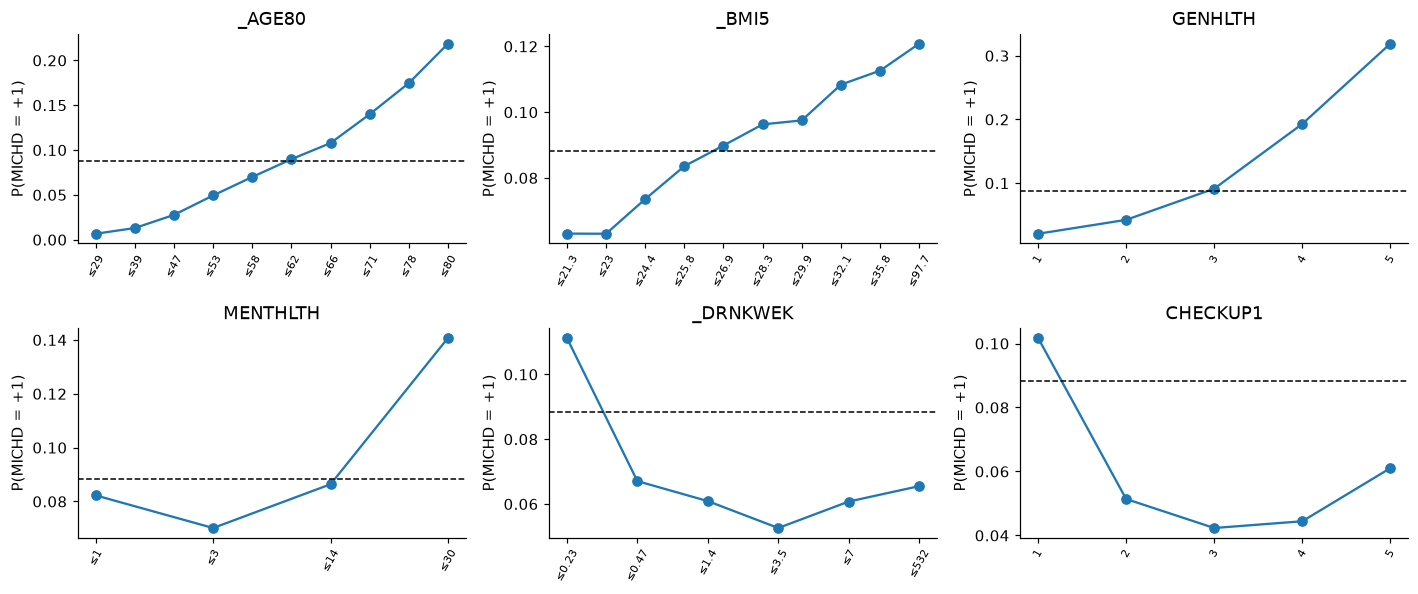


SEX: marginal rate male 0.112 vs female 0.071, MI rank 125; within each age group the male / female rate ratio is 1.0x - 2.1x
_STATE: positive rate from 0.053 to 0.141 across 53 states


In [13]:
SHAPE_FEATURES = ["_AGE80", "_BMI5", "GENHLTH", "MENTHLTH", "_DRNKWEK", "CHECKUP1"]
MAX_LEVELS = 12  # columns with more distinct values are cut into deciles


def rate_by_bin(name):
    '''Return bin labels and P(y = 1) per bin (each level, or deciles of the cleaned column).'''
    values = feature(name, xc)
    known = ~np.isnan(values)
    levels = np.unique(values[known])
    if levels.size <= MAX_LEVELS:
        return [f"{level:g}" for level in levels], [pos_rate(values == level) for level in levels]
    edges = np.unique(np.quantile(values[known], np.linspace(0, 1, 11)))
    bins = np.clip(np.digitize(values[known], edges[1:-1], right=True), 0, len(edges) - 2)
    labels = [f"≤{edges[b + 1]:.3g}" for b in range(len(edges) - 1)]
    return labels, [y01[known][bins == b].mean() if (bins == b).any() else np.nan for b in range(len(labels))]


fig, axes = plt.subplots(2, 3, figsize=(13, 5.5))
for axis, name in zip(axes.ravel(), SHAPE_FEATURES):
    labels, rates = rate_by_bin(name)
    axis.plot(range(len(labels)), rates, "o-")
    axis.set_xticks(range(len(labels)))
    axis.set_xticklabels(labels, rotation=60, fontsize=7)
    axis.axhline(prevalence, c="k", ls="--", lw=1)
    axis.set(title=name, ylabel="P(MICHD = +1)")
    print(f"{name:9s}", " ".join(f"{rate:.3f}" for rate in rates))
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/shape_of_risk.png", bbox_inches="tight")
plt.show()

sex = feature("SEX")
ratios = [pos_rate((sex == 1) & (age_group == g)) / pos_rate((sex == 2) & (age_group == g)) for g in range(1, 14)]
print(f"\nSEX: marginal rate male {pos_rate(sex == 1):.3f} vs female {pos_rate(sex == 2):.3f}, MI rank "
      f"{ranked_names.index('SEX') + 1}; within each age group the male / female rate ratio is "
      f"{min(ratios):.1f}x - {max(ratios):.1f}x")
state_rates = np.array([pos_rate(state == s) for s in states])
print(f"_STATE: positive rate from {state_rates.min():.3f} to {state_rates.max():.3f} across {len(states)} states")

**Takeaways.**
- Age and general health are monotone and close to linear → keep them numeric.
- BMI saturates; mentally unhealthy days and alcohol are J/U-shaped (non-drinkers have a *higher* rate than moderate
  drinkers: people who stopped drinking because of illness), and a recent check-up goes with a higher rate (sick
  people see doctors more). These features are weak, so their shape matters little for F1; non-linear terms
  (squares, binning, a "no drinks" flag) are options to test by CV, not defaults.
- **Confounding works both ways.** Landline users looked riskier only because they are older (3.4). Conversely
  `SEX` looks weak alone (MI rank ≈125), yet at the same age men have up to twice the rate of women → it is an
  important feature once age is in the model. This is why features are not
  selected by marginal MI.
- The positive rate differs by state → one-hot `_STATE` (≈52 columns) is an option to test by CV.

## 6. Redundancy

Several *calculated* columns (prefix `_`) are recodes of raw answers (e.g. `_AGEG5YR`, `_AGE_G`, `_AGE65YR` vs `_AGE80`;
`_RFHYPE5` vs `BPHIGH4`). Duplicates add nothing, make XᵀX singular for `least_squares`, and dilute regularization.

Constant / empty columns: ['CTELENUM', 'COLGHOUS', 'STATERES', 'CTELNUM1', 'CELLFON2', 'CCLGHOUS']


Exact duplicate columns (raw data): [['SEQNO', '_PSU'], ['_CRACE1', '_CPRACE']]


Exact duplicate columns (cleaned data): [['SEQNO', '_PSU'], ['HAVARTH3', '_DRDXAR1'], ['EXERANY2', '_TOTINDA'], ['EXERHMM1', 'PADUR1_'], ['EXERHMM2', 'PADUR2_'], ['HIVTST6', '_AIDTST3'], ['_CRACE1', '_CPRACE']]

44 pairs with |corr| > 0.9 among 129 non-nominal columns with < 50% NaN (median-imputed 50,000-row subsample), e.g.:
  TOLDHI2    ~ _RFCHOL    |r| = 1.000
  HAVARTH3   ~ _DRDXAR1   |r| = 1.000
  EXERHMM1   ~ PADUR1_    |r| = 1.000
  EXERANY2   ~ _TOTINDA   |r| = 1.000
  ASTHMA3    ~ _LTASTH1   |r| = 1.000
  HIVTST6    ~ _AIDTST3   |r| = 1.000
  STRENGTH   ~ STRFREQ_   |r| = 1.000
  EXEROFT1   ~ PAFREQ1_   |r| = 1.000
  WEIGHT2    ~ WTKG3      |r| = 1.000
  FRUIT1     ~ FRUTDA1_   |r| = 1.000
  MAXVO2_    ~ FC60_      |r| = 1.000
  VEGETAB1   ~ VEGEDA1_   |r| = 1.000
  FRUITJU1   ~ FTJUDA1_   |r| = 1.000
  FVGREEN    ~ GRENDAY_   |r| = 1.000
  FVBEANS    ~ BEANDAY_   |r| = 1.000
  ALCDAY5    ~ DROCDY3_   |r| = 1.000
  FVORANG    ~ ORNGDAY_   |r| = 1.000
  HEIGHT3    ~ HTM4      

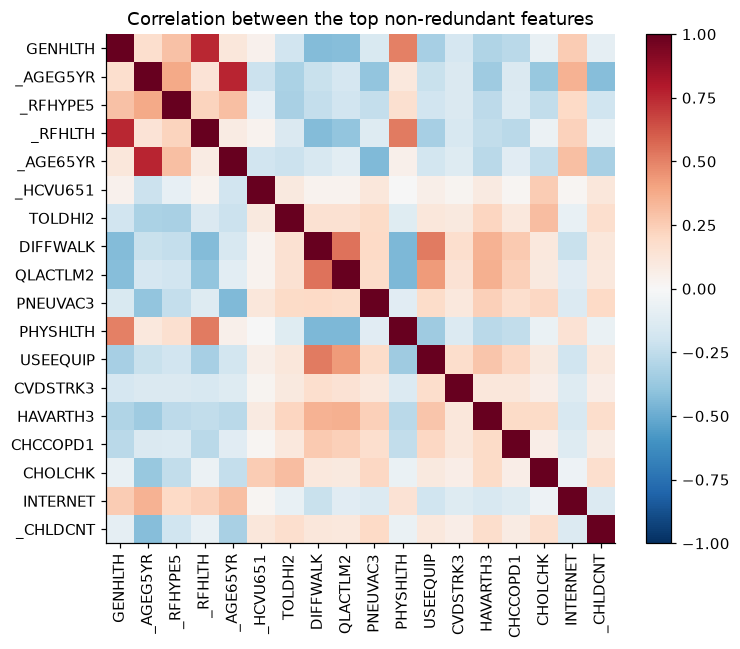

In [14]:
def column_hash(values):
    '''Hash of a column (NaN-aware) used to find exact duplicate columns without copying the matrix.'''
    return hashlib.md5(np.where(np.isnan(values), -1e9, values).tobytes()).hexdigest()


constant = [name for j, name in enumerate(cols) if np.all(np.isnan(x_train[:, j])) or np.nanstd(x_train[:, j]) == 0]
print("Constant / empty columns:", constant)
for label, matrix in [("raw", x_train), ("cleaned", xc)]:
    groups = {}
    for j, name in enumerate(cols):
        if name not in constant:
            groups.setdefault(column_hash(matrix[:, j]), []).append(name)
    print(f"Exact duplicate columns ({label} data):", [group for group in groups.values() if len(group) > 1])

rng = np.random.default_rng(SEED)
rows = rng.choice(N, SUBSAMPLE, replace=False)
candidates = [j for j, name in enumerate(cols)
              if not is_survey[j] and nan_tr[j] < HIGH_NAN and name not in constant and ctype[j] != "nominal"]
sample = xc[rows][:, candidates]
sample = np.where(np.isnan(sample), np.nanmedian(sample, axis=0), sample)
corr_matrix = np.corrcoef(sample, rowvar=False)
upper = np.triu_indices_from(corr_matrix, k=1)
pairs = sorted(((abs(corr_matrix[a, b]), cols[candidates[a]], cols[candidates[b]]) for a, b in zip(*upper)
                if abs(corr_matrix[a, b]) > CORR_REDUNDANT), reverse=True)
print(f"\n{len(pairs)} pairs with |corr| > {CORR_REDUNDANT} among {len(candidates)} non-nominal columns with < {HIGH_NAN:.0%} NaN "
      f"(median-imputed {SUBSAMPLE:,}-row subsample), e.g.:")
for r, a, b in pairs[:20]:
    print(f"  {a:10s} ~ {b:10s} |r| = {r:.3f}")

# Heatmap of the top features after removing redundant ones (greedy, in MI order).
position = {cols[j]: k for k, j in enumerate(candidates)}
top_features = []
for name, *_ in rank:
    if name in LEAKAGE or name not in position:
        continue
    if all(abs(corr_matrix[position[name], position[other]]) < CORR_REDUNDANT for other in top_features):
        top_features.append(name)
    if len(top_features) == 18:
        break
sub = corr_matrix[np.ix_([position[n] for n in top_features], [position[n] for n in top_features])]
off_diagonal = np.abs(sub[np.triu_indices_from(sub, k=1)])
print(f"\nTop {len(top_features)} non-redundant features: |r| median {np.median(off_diagonal):.2f}, "
      f"max {off_diagonal.max():.2f}, pairs > 0.7: {(off_diagonal > 0.7).sum()}")

fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(sub, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(top_features)))
ax.set_xticklabels(top_features, rotation=90)
ax.set_yticks(range(len(top_features)))
ax.set_yticklabels(top_features)
ax.set_title("Correlation between the top non-redundant features")
plt.colorbar(image, fraction=0.046)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/correlation_top_features.png", bbox_inches="tight")
plt.show()

**Takeaways.**
- Drop the constant columns and the exact duplicates (more duplicates appear once the codes are cleaned, e.g.
  `HAVARTH3` = `_DRDXAR1`), and perfect recodes such as `TOLDHI2` ~ `_RFCHOL` (r = −1).
- For every redundant group keep **one** version, preferring the cleanest (e.g. `_AGE80` for age, `WTKG3` / `_BMI5`
  instead of the mixed-unit `WEIGHT2` / `HEIGHT3`, `DROCDY3_` instead of `ALCDAY5`). `MAXVO2_` / `FC60_` are
  deterministic functions of age and sex → drop.
- The heatmap keeps, in MI order, the first feature of each redundant group (so age appears as `_AGEG5YR`; the
  preprocessing keeps `_AGE80`, which carries the same information). Nominal columns are left out because their
  codes have no order.
- Among the top non-redundant features the median |r| is ≈0.2; the most correlated pairs (activity
  limitation questions) reach ≈0.75 → ridge / regularized logistic regression handle the remaining collinearity.

## 7. Leakage suspects

Some questions are only asked to people who already had the disease, or are a consequence of it.

In [15]:
harehab = ~np.isnan(feature("HAREHAB1"))
print(f"HAREHAB1 (cardiac rehab after a heart attack): answered by {harehab.sum()} train rows "
      f"({(~np.isnan(feature('HAREHAB1', x_test))).sum()} test rows), P(y=1 | answered) = {pos_rate(harehab):.3f}, "
      f"covering {harehab.sum() / y01.sum():.1%} of all positives")

# (yes codes, no codes) from the codebook; ASPUNSAF: 1 = yes, 2 = yes (stomach problems), 3 = no
ASPIRIN = {"CVDASPRN": ([1], [2]), "RDUCHART": ([1], [2]), "RDUCSTRK": ([1], [2]),
           "RLIVPAIN": ([1], [2]), "ASPUNSAF": ([1, 2], [3])}
users = feature("CVDASPRN") == 1
print(f"\nAspirin questions (cardiovascular module, a few states). Baseline among daily aspirin users: "
      f"{pos_rate(users):.3f}")
for name, (yes, no) in ASPIRIN.items():
    values = feature(name, xc)
    print(f"  {name:9s} answered {(~np.isnan(values)).mean():5.1%}   yes: {pos_rate(np.isin(values, yes)):.3f}   "
          f"no: {pos_rate(np.isin(values, no)):.3f}   | {DEC[name]['description'][:50]}")
print(f"  RDUCHART / RDUCSTRK / RLIVPAIN are asked only to aspirin users: "
      f"{np.mean(users[~np.isnan(feature('RDUCHART'))]):.0%} of their respondents have CVDASPRN = 1")

strehab = ~np.isnan(feature("STREHAB1"))
print(f"\nSTREHAB1 (rehab after a stroke): answered by {strehab.sum()} rows, P(y=1) = {pos_rate(strehab):.3f}"
      f" -> comorbidity (stroke), not the label")

HAREHAB1 (cardiac rehab after a heart attack): answered by 773 train rows (238 test rows), P(y=1 | answered) = 1.000, covering 2.7% of all positives

Aspirin questions (cardiovascular module, a few states). Baseline among daily aspirin users: 0.208
  CVDASPRN  answered  4.3%   yes: 0.208   no: 0.045   | Do you take aspirin daily or every other day?
  RDUCHART  answered  1.2%   yes: 0.234   no: 0.066   | Do you take aspirin to reduce the chance of a hear
  RDUCSTRK  answered  1.2%   yes: 0.223   no: 0.172   | Do you take aspirin to reduce the chance of a stro
  RLIVPAIN  answered  1.3%   yes: 0.151   no: 0.224   | Do you take aspirin to relieve pain?
  ASPUNSAF  answered  3.0%   yes: 0.135   no: 0.033   | Do you have a health problem or condition that mak
  RDUCHART / RDUCSTRK / RLIVPAIN are asked only to aspirin users: 100% of their respondents have CVDASPRN = 1

STREHAB1 (rehab after a stroke): answered by 517 rows, P(y=1) = 0.358 -> comorbidity (stroke), not the label


**Takeaways.**
- `HAREHAB1`: whoever answered it had a heart attack (100% precision), but it covers only ≈2.7% of the positives
  and it exists for ≈240 test rows. It is a direct consequence of the label, not a predictor.
- Aspirin: daily aspirin use (`CVDASPRN`) is a treatment of heart disease (*reverse causation*), and so is the
  follow-up asked only to aspirin users (*to reduce the chance of a heart attack*); the other follow-ups and
  `ASPUNSAF` (asked to non-users) belong to the same module.
- `STREHAB1` (rehab after a stroke) is a comorbidity, like `CVDSTRK3`: legitimate.
- **Decision:** exclude `HAREHAB1` and the aspirin questions from the main model and report their effect in a
  separate ablation row, so that the choice is transparent in the report.

## 8. Distributions and outliers of continuous features

Statistics on the cleaned data (codes mapped, units converted, `_DRNKWEK` / `DROCDY3_` rescaled from ×100,
structural zeros filled).

column       NaN     min  median      p99       max   skew   meaning
_AGE80        0%    18.0    58.0     80.0      80.0   -0.4   Imputed Age value collapsed above 80
_BMI5         8%    12.0    26.9     49.4      97.7    2.3   Body Mass Index (BMI)
WTKG3         7%    22.7    77.6    145.2     289.9    1.7   Reported weight in kilograms
HTIN4         4%    36.0    66.0     76.0      95.0    0.2   Reported height in inches
PHYSHLTH      2%     0.0     0.0     30.0      30.0    2.2   Now thinking about your physical healt
MENTHLTH      2%     0.0     0.0     30.0      30.0    2.6   Now thinking about your mental health;
POORHLTH      1%     0.0     0.0     30.0      30.0    3.0   During the past 30 days; for about how
CHILDREN      1%     0.0     0.0      4.0      77.0    4.1   How many children less than 18 years o
_DRNKWEK      6%     0.0     0.2     28.0     532.0   18.0   Calculated total number of alcoholic b
DROCDY3_      5%     0.0     0.0      1.0       1.0    2.0   Drink-occasi

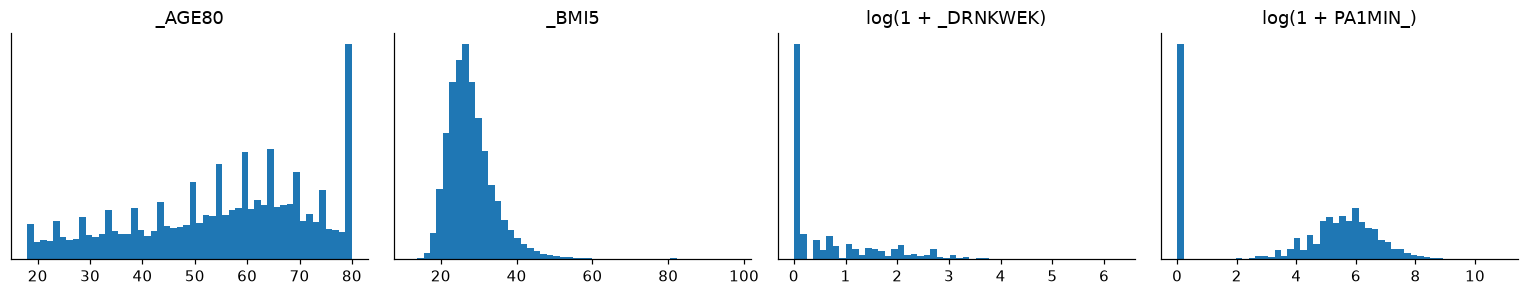

In [16]:
CONTINUOUS = ["_AGE80", "_BMI5", "WTKG3", "HTIN4", "PHYSHLTH", "MENTHLTH", "POORHLTH", "CHILDREN", "_DRNKWEK",
              "DROCDY3_", "AVEDRNK2", "MAXDRNKS", "PA1MIN_", "PA1VIGM_", "STRFREQ_", "_FRUTSUM", "_VEGESUM"]
print(f"{'column':10s}{'NaN':>6s}{'min':>8s}{'median':>8s}{'p99':>9s}{'max':>10s}{'skew':>7s}   meaning")
for name in CONTINUOUS:
    values = feature(name, xc)
    known = values[~np.isnan(values)]
    q = np.percentile(known, [0, 50, 99, 100])
    skew = np.mean(((known - known.mean()) / known.std()) ** 3)
    meaning = DEC[name]["description"][:38]
    print(f"{name:10s}{np.isnan(values).mean():6.0%}{q[0]:8.1f}{q[1]:8.1f}{q[2]:9.1f}{q[3]:10.1f}{skew:7.1f}   {meaning}")

fig, ax = plt.subplots(1, 4, figsize=(14, 2.8))
for axis, name, use_log in zip(ax, ["_AGE80", "_BMI5", "_DRNKWEK", "PA1MIN_"], [False, False, True, True]):
    values = feature(name, xc)
    values = values[~np.isnan(values)]
    axis.hist(np.log1p(values) if use_log else values, bins=50)
    axis.set(title=f"log(1 + {name})" if use_log else name, yticks=[])
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/distributions.png", bbox_inches="tight")
plt.show()

**Takeaways.**
- Age, BMI, weight and height are well behaved.
- Counts such as drinks per week and minutes of activity are **heavily right-skewed** with extreme maxima (valid
  codebook values, e.g. "76 or more drinks", but implausible). The minimum is 0 for almost all of them, so only the
  upper tail matters → apply `log1p` to these counts; otherwise a few extreme values dominate the
  standardization and the gradient. Clipping at the train 99th percentile is optional (after `log1p`); it should
  not be applied blindly to BMI or weight, whose top 1% still has a higher disease rate.
- After cleaning, every feature must be **standardized** (train mean / std), because GD uses a single step size γ.

## 9. Train / test shift

In [17]:
xc_test = fill_structural(clean_codes(x_test), x_test)
mean_train, mean_test = np.nanmean(xc, axis=0), np.nanmean(xc_test, axis=0)
std_train = np.nanstd(xc, axis=0)
compared = ~is_survey & (nan_tr < 0.9) & (std_train > 0)  # near-empty columns have unstable means
shift = np.abs(mean_train - mean_test)[compared] / std_train[compared]
names = np.array(cols)[compared]
largest = np.argsort(-shift)[:5]
print(f"{compared.sum()} non-survey columns with < 90% NaN")
print("Largest |mean_train - mean_test| / std:", ", ".join(f"{n} {s:.3f}" for n, s in zip(names[largest], shift[largest])))
print(f"Columns with a difference > {SHIFT_MAX} std: {(shift > SHIFT_MAX).sum()}")
del xc_test

193 non-survey columns with < 90% NaN
Largest |mean_train - mean_test| / std: STOPSMK2 0.022, BLDSTOOL 0.017, CASTHDX2 0.012, _CHISPNC 0.011, WHRTST10 0.011
Columns with a difference > 0.05 std: 0


**Takeaway.** No shift: the largest difference is a few hundredths of a standard deviation (near-empty columns,
whose means rest on a handful of rows, are excluded). Train and test are a random split, so cross-validation on
train is a reliable estimate of the test F1.

## 10. Imbalance: why the threshold matters

Quick illustration (not the final model): 15 strong, non-redundant risk factors (yes/no questions recoded to 1/0,
nominal BPHIGH4 / DIABETE3 reduced to *yes* vs the rest), median imputation and standardization fitted on the
training part, stratified 80/20 split. We train ridge regression on ±1 labels and logistic regression (both from
`implementations.py`) and look at F1 as a function of the decision threshold.

Validation: 5795 positives
Ridge   : threshold 0   -> F1 0.062 (302 predicted positives) | best F1 0.400 at -0.60 (= 0.20 on the 0-1 scale)
Logistic: threshold 0.5 -> F1 0.216 (1423 predicted positives) | best F1 0.419 at 0.20 (theory F1*/2 = 0.21)
split thr (train)  F1 val  thr (val)  best F1 val


    1        0.19   0.416       0.20        0.417


    2        0.19   0.417       0.20        0.418


    3        0.19   0.414       0.19        0.414


    4        0.19   0.422       0.19        0.422

Class weights (first split), threshold tuned on the training part:


  positive weight   1.0: threshold 0.19, validation F1 0.419


  positive weight   3.0: threshold 0.41, validation F1 0.418


  positive weight  10.3: threshold 0.70, validation F1 0.416


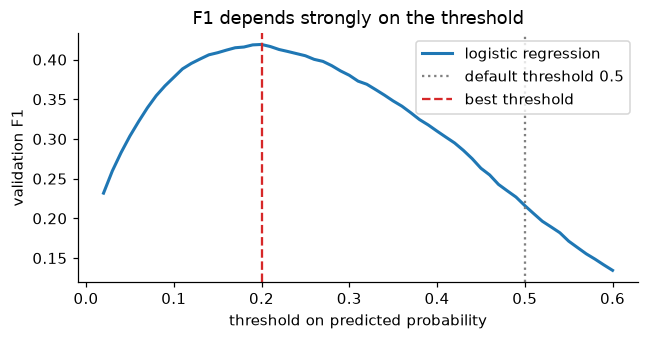

In [18]:
# name -> code meaning "yes" (recoded to 1, other answers to 0), or None to keep the numeric value
DEMO_FEATURES = {"GENHLTH": None, "_AGE80": None, "PHYSHLTH": None, "_BMI5": None, "SEX": 1, "BPHIGH4": 1,
                 "TOLDHI2": 1, "DIFFWALK": 1, "CVDSTRK3": 1, "DIABETE3": 1, "CHCKIDNY": 1, "CHCCOPD1": 1,
                 "HAVARTH3": 1, "QLACTLM2": 1, "SMOKE100": 1}
RIDGE_LAMBDA, LOGISTIC_ITERS, LOGISTIC_GAMMA = 1e-4, 300, 0.5


def demo_matrix():
    '''Build the demo design matrix from the cleaned data (NaN kept, imputed later).'''
    columns = []
    for name, yes in DEMO_FEATURES.items():
        values = feature(name, xc)
        columns.append(values if yes is None else np.where(np.isnan(values), np.nan, (values == yes) * 1.0))
    return np.column_stack(columns)


def stratified_split(y, test_share, seed):
    '''Return train / test indices keeping the positive rate of y in both parts.'''
    rng = np.random.default_rng(seed)
    positives, negatives = np.where(y == 1)[0], np.where(y == -1)[0]
    test = np.concatenate([rng.choice(positives, int(len(positives) * test_share), replace=False),
                           rng.choice(negatives, int(len(negatives) * test_share), replace=False)])
    return np.setdiff1d(np.arange(len(y)), test), test


def f1_curve(y_true, scores, thresholds):
    '''Return the F1 score obtained with each threshold.'''
    return np.array([precision_recall_f1(y_true, predict_labels(scores, t))[2] for t in thresholds])


def prepare(X, train):
    '''Median-impute and standardize X with statistics of the training rows, then add a bias column.'''
    X = np.where(np.isnan(X), np.nanmedian(X[train], axis=0), X)
    mean, std = X[train].mean(axis=0), X[train].std(axis=0)
    return np.c_[np.ones(len(X)), (X - mean) / std]


X_demo = demo_matrix()
train, val = stratified_split(y_train, 0.2, SEED)
tx = prepare(X_demo, train)
w_ridge, _ = ridge_regression(y_train[train], tx[train], RIDGE_LAMBDA)
w_logistic, _ = logistic_regression(y01[train], tx[train], np.zeros(tx.shape[1]), LOGISTIC_ITERS, LOGISTIC_GAMMA)
score_ridge = tx[val] @ w_ridge
prob_logistic = sigmoid(tx[val] @ w_logistic)

thresholds_ridge = np.linspace(-1, 0.5, 61)
thresholds_prob = np.linspace(0.02, 0.6, 59)
f1_ridge = f1_curve(y_train[val], score_ridge, thresholds_ridge)
f1_logistic = f1_curve(y_train[val], prob_logistic, thresholds_prob)
best_r, best_l = int(np.argmax(f1_ridge)), int(np.argmax(f1_logistic))
default_r = precision_recall_f1(y_train[val], predict_labels(score_ridge, 0.0))[2]
default_l = precision_recall_f1(y_train[val], predict_labels(prob_logistic, 0.5))[2]
print(f"Validation: {int((y_train[val] == 1).sum())} positives")
print(f"Ridge   : threshold 0   -> F1 {default_r:.3f} ({int((score_ridge >= 0).sum())} predicted positives) | "
      f"best F1 {f1_ridge[best_r]:.3f} at {thresholds_ridge[best_r]:.2f} (= {(thresholds_ridge[best_r] + 1) / 2:.2f} "
      f"on the 0-1 scale)")
print(f"Logistic: threshold 0.5 -> F1 {default_l:.3f} ({int((prob_logistic >= 0.5).sum())} predicted positives) | "
      f"best F1 {f1_logistic[best_l]:.3f} at {thresholds_prob[best_l]:.2f} (theory F1*/2 = {f1_logistic[best_l] / 2:.2f})")

# Robustness to the random split (each split refits imputation and scaling). The threshold is chosen on the
# TRAINING part, as in cross-validation, and compared with the best threshold chosen on the validation part.
print(f"{'split':>5s}{'thr (train)':>12s}{'F1 val':>8s}{'thr (val)':>11s}{'best F1 val':>13s}")
for seed in range(1, 5):
    train_s, val_s = stratified_split(y_train, 0.2, seed)
    tx_s = prepare(X_demo, train_s)
    w_s, _ = logistic_regression(y01[train_s], tx_s[train_s], np.zeros(tx_s.shape[1]), LOGISTIC_ITERS, LOGISTIC_GAMMA)
    curve_train = f1_curve(y_train[train_s], sigmoid(tx_s[train_s] @ w_s), thresholds_prob)
    curve_val = f1_curve(y_train[val_s], sigmoid(tx_s[val_s] @ w_s), thresholds_prob)
    chosen, best = int(np.argmax(curve_train)), int(np.argmax(curve_val))
    print(f"{seed:5d}{thresholds_prob[chosen]:12.2f}{curve_val[chosen]:8.3f}{thresholds_prob[best]:11.2f}{curve_val[best]:13.3f}")


def weighted_logistic(y, tx, positive_weight, max_iters, gamma):
    '''Logistic regression by GD where each positive sample counts positive_weight times (weights normalized to mean 1).'''
    sample_weight = np.where(y == 1, positive_weight, 1.0)
    sample_weight /= sample_weight.mean()
    w = np.zeros(tx.shape[1])
    for _ in range(max_iters):
        w -= gamma * tx.T @ (sample_weight * (sigmoid(tx @ w) - y)) / len(y)
    return w


print("\nClass weights (first split), threshold tuned on the training part:")
thresholds_weighted = np.linspace(0.02, 0.98, 97)  # weighted probabilities are shifted upwards
for positive_weight in [1.0, 3.0, (1 - prevalence) / prevalence]:
    w_c = weighted_logistic(y01[train], tx[train], positive_weight, LOGISTIC_ITERS, LOGISTIC_GAMMA)
    chosen = thresholds_weighted[int(np.argmax(f1_curve(y_train[train], sigmoid(tx[train] @ w_c), thresholds_weighted)))]
    f1_val = precision_recall_f1(y_train[val], predict_labels(sigmoid(tx[val] @ w_c), chosen))[2]
    print(f"  positive weight {positive_weight:5.1f}: threshold {chosen:.2f}, validation F1 {f1_val:.3f}")

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(thresholds_prob, f1_logistic, lw=2, label="logistic regression")
ax.axvline(0.5, c="gray", ls=":", label="default threshold 0.5")
ax.axvline(thresholds_prob[best_l], c="tab:red", ls="--", label="best threshold")
ax.set(xlabel="threshold on predicted probability", ylabel="validation F1",
       title="F1 depends strongly on the threshold")
ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/f1_vs_threshold.png", bbox_inches="tight")
plt.show()

**Takeaways.**
- With the default threshold (0.5 for probabilities, 0 for ±1 regression scores) the models predict far fewer
  positives than there are (≈300 and ≈1,400 for 5,795 actual positives) → F1 0.06 (ridge) and 0.22 (logistic).
- Tuning the threshold gives F1 ≈ 0.40 (ridge) and ≈ 0.42 (logistic). The best threshold is 0.19–0.20 on all five
  splits, as predicted by theory for calibrated probabilities: optimum ≈ F1*/2 (Lipton et al., 2014,
  [arXiv:1402.1892](https://arxiv.org/abs/1402.1892)). Ridge's best threshold −0.60 on the ±1 scale is the same 0.20
  on the 0–1 scale.
- Choosing the threshold on the **training** part gives almost the same threshold and validation F1 as choosing it on
  the validation part itself (difference ≈ 0.001) → the protocol "threshold tuned on the training folds" is unbiased
  and loses nothing.
- Class weights only move the best threshold (higher weight → higher threshold) and do not improve F1 once the
  threshold is tuned: for a linear model, weighting mainly shifts the intercept. Undersampling the negatives has the
  same effect and throws data away.
- **Decisions:** (1) tune the threshold by cross-validation, choosing it on the training folds only; (2) no class
  weights or undersampling by default (kept only as an option, to re-check with the final features);
  (3) use **stratified** folds so every fold keeps ≈8.8% positives.

## 11. Decisions for `preprocessing.py`

| # | Step | Decision | Evidence |
|---|---|---|---|
| 1 | Survey columns | Drop ids, dates, sequence numbers, phone-screening block (incl. landline flag), survey weights | §2, §3.4 |
| 2 | Leakage | Exclude 7 post-event questions (rehab `HAREHAB1`, `STREHAB1` and secondary prevention aspirin `CVDASPRN`, `RDUCHART`, `RDUCSTRK`, `ASPUNSAF`, `RLIVPAIN`) from the official screening model to prevent reverse causality; benchmarked in separate audit track | §7 |
| 3 | Special codes | Per column from `eda/special_codes.json`: don't know / refused / not applicable → NaN, none / never → 0, *never* coded 8 after a 1–4 scale (`CHECKUP1`) → 5, unit codes converted, ×100 columns rescaled | §4, §5 |
| 4 | Structural NaN | Fill skip-logic NaN with their logical value (BPMEDS = no, INSULIN = no, CHOLCHK = never, drinks = 0, POORHLTH = 0, PA minutes = 0, …) | §3.3 |
| 5 | Drop columns | Constant, exact duplicates, redundant recodes and exact sums (keep one per group), > 80% NaN unless informative (threshold tuned by CV). No top-k selection by marginal MI | §3.4, §5.2, §5.3, §6 |
| 6 | Missing indicators | Add a 0/1 "was missing" column for kept columns where P(y\|NaN) differs from P(y\|obs) (not needed after a structural fill) | §3.2, §4 |
| 7 | Imputation | Median (numeric / ordinal) or mode (nominal), computed on the training data / folds only | §3.1 |
| 8 | Encoding | Yes/no → 1/0; ordinal kept numeric; nominal (incl. BPHIGH4, DIABETE3) → one-hot (drop one level if using `least_squares`) | §2, §5.1 |
| 9 | Tails | `log1p` for skewed counts; clipping at the train 99th percentile optional (tested by CV) | §8 |
| 10 | Scaling | Standardize with train mean / std, then add the bias column | §8 |
| 11 | Imbalance | Stratified k-fold CV; tune the decision threshold for F1 on training folds. Class weights / undersampling bring nothing on top of it (kept as an option) | §1, §10 |
| 12 | Validation | Train and test have the same distribution → CV F1 is a reliable proxy for AIcrowd | §3.1, §9 |
| 13 | Optional, by CV | Non-linear terms (squares / binning / *no drinks* flag), one-hot `_STATE` | §5.3 |

The per-column version of this table (type, NaN rate, codes, positive rates, MI, redundancy, recommended action)
is `eda/column_decisions.csv`.